# Fourier, espectro e filtros

**Eletrônica · Ciência da Computação · IFSP Jacareí · Prof. Tardelli Stekel**

---

Hoje você vai começar **do zero**, com uma senoide, e terminar **achando o ciclo do Sol e uma palavra escondida em uma imagem**.
A receita é sempre a mesma:

**olhar o sinal  →  olhar o espectro  →  escolher o filtro  →  filtrar  →  conferir**

A atividade tem dois tipos de tarefa:
* 🔁 **Igual ao professor:** você repete o que viu na demonstração. Confira se os seus gráficos saem iguais.
* ⭐ **A mais:** a mesma ideia, em coisas novas.

| Parte | O que você vai fazer | Tempo |
|---|---|---|
| Parte 1 | 🔁 Senoide, FFT e soma de senoides · ⭐ Sinal misterioso e primeiro filtro | 20 min |
| Parte 2 | 🔁 Onda quadrada · ⭐ Tomada, retificador, clock, violão e temperatura | 20 min |
| Parte 3 | 🔁 CO₂ · ⭐ Missão 1: coração · ⭐ Missão 2: energia, maré e o ciclo do Sol | 50 min |
| Parte 4 | 🔁 Limpar a voz, só olhando | 10 min |
| Parte 5 | 🔁 Filtros na foto · ⭐ Missão 4: a palavra escondida | 25 min |
| Extra | ⭐ Missão 3: o código em tons de telefone (se o tempo acabar, termine em casa) | 20 min |

### Como usar
* Rode as células **na ordem**, com **Shift + Enter**.
* Onde aparecer `___`, troque pelo que se pede e rode de novo. ✅ = certo · ❌ = revise · ⏳ = falta algo antes.
* Em Python, o decimal usa **ponto**: escreva `0.5`, e não `0,5`.
* Cada **Entrega** (📸 print ou ✍️ resposta) vai para a **Folha de Entrega**, na ordem.
* **Cada grupo tem dados diferentes.** A resposta do grupo vizinho não serve para o seu.

In [ ]:
GRUPO = 1      # ⬅️ TROQUE PELO NÚMERO DO SEU GRUPO e rode esta célula

print('Grupo', GRUPO)

### Ferramentas
Rode a célula abaixo uma vez. Ela prepara as bibliotecas e as funções que você vai chamar. O código fica recolhido, porque não precisa ler agora.

In [3]:
#@title Ferramentas da aula: rode esta célula (clique duas vezes para ver o código)
import os, hashlib, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.io import wavfile
from scipy.signal import find_peaks
from scipy.ndimage import maximum_filter

plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': 0.25,
                     'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
AZUL, LARANJA, CINZA, VERDE = '#2F6DB5', '#C2571A', '#9AA0A6', '#5B9B2F'
___ = None      # é isto que você vai substituir nos desafios

BASE = 'https://raw.githubusercontent.com/tardellirs/aula-fourier-espectro/main/'

def preenchido(v):
    '''True se v já é um número. Vazio, texto ou 0,5 com vírgula ainda não servem.'''
    return isinstance(v, (int, float, np.number))

def _aviso(v, nome='valor'):
    if v is None:
        print(f'⏳ {nome}: ainda falta preencher')
    elif isinstance(v, tuple):
        print(f'❌ {nome}: em Python, o decimal usa ponto. Escreva 0.5, e não 0,5')
    else:
        print(f'❌ {nome}: escreva só um número, sem aspas')

def baixar(caminho):
    '''Usa o arquivo local; se não houver, baixa do repositório da aula.'''
    if not os.path.exists(caminho):
        os.makedirs(os.path.dirname(caminho), exist_ok=True)
        urllib.request.urlretrieve(BASE + caminho, caminho)
    return caminho

# ---------- espectro ----------
def espectro(sinal, fs):
    '''Devolve (f, A): cada frequência e quanto dela existe no sinal.'''
    if sinal is None:
        return None, None
    x = np.asarray(sinal, float)
    x = x - x.mean()
    A = np.abs(np.fft.rfft(x)) * 2 / len(x)
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, A

def picos(f, A, n=3, f_min=0, f_max=None):
    '''As n frequências com os maiores picos, da maior para a menor.'''
    if f is None or n is None:
        return [None, None]
    f_max = f[-1] if f_max is None else f_max
    m = (f >= f_min) & (f <= f_max)
    fm, Am = f[m], A[m]
    i, _ = find_peaks(Am)
    i = i[np.argsort(Am[i])[::-1][:n]]
    return [float(v) for v in fm[i]]

# ---------- filtros: zeram uma parte do espectro e voltam para o tempo ----------
def _filtra(sinal, fs, manter):
    X = np.fft.rfft(np.asarray(sinal, float))
    f = np.fft.rfftfreq(len(sinal), 1 / fs)
    X[~manter(f)] = 0
    return np.fft.irfft(X, len(sinal))

def passa_baixa(sinal, fs, f_corte):
    if not preenchido(f_corte) or sinal is None:
        print('⏳ complete os valores do filtro'); return None
    return _filtra(sinal, fs, lambda f: f <= f_corte)

def passa_alta(sinal, fs, f_corte):
    if not preenchido(f_corte) or sinal is None:
        print('⏳ complete os valores do filtro'); return None
    return _filtra(sinal, fs, lambda f: f >= f_corte)

def passa_faixa(sinal, fs, f_baixo, f_alto):
    if not (preenchido(f_baixo) and preenchido(f_alto)) or sinal is None:
        print('⏳ complete os valores do filtro'); return None
    return _filtra(sinal, fs, lambda f: (f >= f_baixo) & (f <= f_alto))

def rejeita_faixa(sinal, fs, f_baixo, f_alto):
    if not (preenchido(f_baixo) and preenchido(f_alto)) or sinal is None:
        print('⏳ complete os valores do filtro'); return None
    return _filtra(sinal, fs, lambda f: (f < f_baixo) | (f > f_alto))

# ---------- gráficos ----------
def ver_sinal(sinal, fs, titulo='', de=0, ate=None, cor=AZUL, unidade='s'):
    if sinal is None:
        print('⏳ complete o passo anterior'); return
    t = np.arange(len(sinal)) / fs
    ate = t[-1] if ate is None else ate
    m = (t >= de) & (t <= ate)
    plt.plot(t[m], np.asarray(sinal)[m], color=cor, lw=1.2)
    plt.xlabel(f'tempo ({unidade})'); plt.ylabel('valor'); plt.title(titulo); plt.show()

def ver_espectro(f, A, titulo='', de=0, ate=None, cor=AZUL, marcar=0):
    '''marcar = quantos picos escrever no gráfico.'''
    if f is None:
        print('⏳ complete o passo anterior'); return
    ate = f[-1] if ate is None else ate
    m = (f >= de) & (f <= ate)
    plt.plot(f[m], A[m], color=cor, lw=1.4)
    for p in picos(f, A, n=marcar, f_min=de, f_max=ate) if marcar else []:
        a = A[np.argmin(np.abs(f - p))]
        plt.annotate(f'{p:.4g} Hz', (p, a), xytext=(4, 4), textcoords='offset points', fontsize=10)
    plt.margins(y=0.12)
    plt.xlabel('frequência (Hz)'); plt.ylabel('quanto tem'); plt.title(titulo); plt.show()

def ver_periodos(f, A, picos_f, unidade, de, ate, titulo=''):
    '''Mesmo espectro, mas com o eixo em PERÍODO (1/f).'''
    m = (f > 0) & (1 / np.maximum(f, 1e-12) >= de) & (1 / np.maximum(f, 1e-12) <= ate)
    plt.plot(1 / f[m], A[m], color=AZUL, lw=1.4)
    for p in picos_f:
        a = A[np.argmin(np.abs(f - p))]
        vizinho = any(1 / p < 1 / q < 1.1 / p for q in picos_f)     # tem outro pico logo à direita?
        plt.annotate(f'{1/p:.4g} {unidade}', (1 / p, a), xytext=(-4, 4) if vizinho else (4, 4),
                     ha='right' if vizinho else 'left', textcoords='offset points', fontsize=10)
    plt.xscale('log')
    marcas = [v for v in [1, 2, 3, 5, 8, 10, 12, 15, 20, 25, 30, 40, 50, 100, 200, 400] if de <= v <= ate]
    plt.xticks(marcas, [str(v) for v in marcas]); plt.minorticks_off()
    plt.margins(y=0.12)
    plt.xlabel(f'período ({unidade})'); plt.ylabel('quanto tem'); plt.title(titulo); plt.show()

def ver_filtro(f, A, filtro, a=None, b=None, titulo='', de=0, ate=None, em_periodo=False, unidade='Hz', topo=None):
    '''Espectro com o filtro desenhado: verde é o que passa, cinza é o que é cortado.
    filtro: 'passa-baixa', 'passa-alta' ou 'passa-faixa', com a frequência de corte em a (e b, na faixa).'''
    if f is None or (isinstance(filtro, str) and (not preenchido(a) or (filtro == 'passa-faixa' and not preenchido(b)))):
        print('⏳ complete os valores do filtro'); return
    regras = {'passa-baixa': lambda v: v <= a, 'passa-alta': lambda v: v >= a, 'passa-faixa': lambda v: (v >= a) & (v <= (b or 0))}
    passa = regras[filtro](f) if isinstance(filtro, str) else filtro(f)
    if em_periodo:
        ok = f > 0
        x, y, passa = (1 / f[ok])[::-1], A[ok][::-1], passa[ok][::-1]
    else:
        x, y = f, A
    ate = x[-1] if ate is None else ate
    m = (x >= de) & (x <= ate)
    topo = y[m].max() * 1.1 if topo is None else topo
    plt.fill_between(x[m], 0, topo, where=passa[m], color=VERDE, alpha=0.22, lw=0, label='passa', step='mid')
    plt.fill_between(x[m], 0, topo, where=~passa[m], color=CINZA, alpha=0.45, lw=0, label='é cortado', step='mid')
    plt.plot(x[m], np.minimum(y[m], topo), color=AZUL, lw=1.3)
    plt.ylim(0, topo); plt.legend(loc='upper right', framealpha=0.9)
    if em_periodo:
        plt.xscale('log')
        marcas = [v for v in [3, 5, 8, 12, 24, 50, 100, 200, 400] if de <= v <= ate]
        plt.xticks(marcas, [str(v) for v in marcas]); plt.minorticks_off(); plt.xlabel(f'período ({unidade})')
    else:
        plt.xlabel('frequência (Hz)')
    plt.ylabel('quanto tem'); plt.title(titulo); plt.show()

def ver_ciclo_ou_harmonico(sinal, meses, anos):
    '''A forma do ano médio, com 12 meses e com 12 + 6 meses, e a mesma forma em cada década.'''
    if sinal is None:
        print('⏳ complete o passo anterior'); return
    nomes = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']
    def ano_medio(escolha):
        return np.array([sinal[escolha & (meses == m)].mean() for m in range(1, 13)])
    def so_ate(y, k):
        Y = np.fft.rfft(y); Y[k + 1:] = 0
        return np.fft.irfft(Y, 12)
    medio = ano_medio(np.ones(len(sinal), bool))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(nomes, medio, 'o', color=AZUL, ms=7, label='o ano médio')
    ax[0].plot(nomes, so_ate(medio, 1), color=CINZA, lw=2, label='só 12 meses')
    ax[0].plot(nomes, so_ate(medio, 2), color=LARANJA, lw=2, label='12 + 6 meses')
    ax[0].set_title('A forma do ano'); ax[0].set_ylabel('CO₂ (variação)'); ax[0].legend()
    print('Altura do pico de 6 meses dividida pela do pico de 12 meses, em cada década:')
    for inicio, cor in zip([1960, 1980, 2000, 2015], [CINZA, VERDE, AZUL, LARANJA]):
        y = ano_medio((anos >= inicio) & (anos < inicio + 10))
        Y = np.abs(np.fft.rfft(y))
        print(f'  {inicio} a {inicio + 9}: {Y[2] / Y[1]:.2f}')
        ax[1].plot(nomes, y, color=cor, lw=2, label=f'{inicio} a {inicio + 9}')
    ax[1].set_title('A mesma forma em cada década'); ax[1].legend()
    plt.tight_layout(); plt.show()

# ---------- tons de telefone ----------
LINHAS, COLUNAS = [697, 770, 852, 941], [1209, 1336, 1477]
TECLADO = [['1', '2', '3'], ['4', '5', '6'], ['7', '8', '9'], ['*', '0', '#']]

def tecla(f1, f2):
    '''Recebe as duas frequências e devolve a tecla do telefone.'''
    if f1 is None or f2 is None:
        return '?'
    baixa, alta = min(f1, f2), max(f1, f2)
    l = int(np.argmin([abs(baixa - v) for v in LINHAS]))
    c = int(np.argmin([abs(alta - v) for v in COLUNAS]))
    if abs(baixa - LINHAS[l]) > 15 or abs(alta - COLUNAS[c]) > 15:
        return '?'
    return TECLADO[l][c]

# ---------- imagens ----------
def ler_imagem(caminho):
    return np.asarray(Image.open(baixar(caminho)), float)

def ver_imagens(*pares, tamanho=4.6):
    '''ver_imagens(("título", imagem), ("título", imagem), ...)'''
    fig, ax = plt.subplots(1, len(pares), figsize=(tamanho * len(pares), tamanho), squeeze=False)
    for a, (titulo, im) in zip(ax[0], pares):
        a.imshow(im, cmap='gray'); a.set_title(titulo); a.axis('off')
    plt.tight_layout(); plt.show()

def _mascara(forma, regra):
    y, x = np.mgrid[-(forma[0] // 2):forma[0] - forma[0] // 2, -(forma[1] // 2):forma[1] - forma[1] // 2]
    return regra(x, y)

def _aplica(im, mascara):
    F = np.fft.fftshift(np.fft.fft2(im))
    return np.fft.ifft2(np.fft.ifftshift(F * mascara)).real

def passa_baixa_imagem(im, raio):
    return _aplica(im, _mascara(im.shape, lambda x, y: x**2 + y**2 <= raio**2))

def passa_alta_imagem(im, raio):
    return _aplica(im, _mascara(im.shape, lambda x, y: x**2 + y**2 > raio**2))

def ver_filtro_imagem(im, raio):
    '''Em cima, a imagem. Embaixo, o pedaço do espectro que o filtro guardou.'''
    n, m = im.shape
    F = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(im))))
    dentro = _mascara(im.shape, lambda x, y: x**2 + y**2 <= raio**2)
    ext = (-m / 2 - .5, m / 2 - .5, -n / 2 - .5, n / 2 - .5)
    colunas = [('Original', im, F), (f'Passa-baixa (raio {raio})', passa_baixa_imagem(im, raio), np.where(dentro, F, 0)),
               (f'Passa-alta (raio {raio})', passa_alta_imagem(im, raio), np.where(dentro, 0, F))]
    fig, ax = plt.subplots(2, 3, figsize=(13, 8.6))
    for k, (nome, imagem, esp) in enumerate(colunas):
        ax[0, k].imshow(imagem, cmap='gray'); ax[0, k].set_title(nome); ax[0, k].axis('off')
        ax[1, k].imshow(esp, cmap='magma', origin='lower', vmin=np.percentile(F, 50), vmax=F.max(), extent=ext)
        ax[1, k].set_title('O espectro inteiro' if k == 0 else 'O que o filtro guardou'); ax[1, k].grid(False)
        ax[1, k].set_xlabel('frequência em x'); ax[1, k].set_ylabel('frequência em y')
    plt.tight_layout(); plt.show()

def ver_espectro_imagem(im, zoom=None, titulo='Espectro da imagem'):
    '''O centro são as frequências baixas. Quanto mais longe do centro, mais alta a frequência.'''
    F = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(im))))
    n, m = im.shape
    if zoom:
        F = maximum_filter(F, size=3)       # engrossa cada ponto para ficar fácil de ver
    plt.figure(figsize=(7, 7))
    plt.imshow(F, cmap='magma', origin='lower', vmin=np.percentile(F, 50), extent=(-m / 2 - .5, m / 2 - .5, -n / 2 - .5, n / 2 - .5))
    if zoom:
        plt.xlim(-zoom, zoom); plt.ylim(-zoom, zoom); plt.xticks(range(-zoom, zoom + 1, 10), rotation=90); plt.yticks(range(-zoom, zoom + 1, 10))
    plt.grid(color='white', alpha=0.2)
    plt.xlabel('frequência em x (ciclos por imagem)'); plt.ylabel('frequência em y (ciclos por imagem)'); plt.title(titulo); plt.show()

def apagar_pontos(im, pontos, raio=5):
    '''Apaga do espectro cada ponto (fx, fy) e também o seu espelho (-fx, -fy).'''
    for p in pontos:
        if None in p:
            print('⏳ complete as coordenadas dos pontos'); return None
    def regra(x, y):
        m = np.ones_like(x, bool)
        for fx, fy in pontos:
            m &= (x - fx)**2 + (y - fy)**2 > raio**2
            m &= (x + fx)**2 + (y + fy)**2 > raio**2
        return m
    return _aplica(im, _mascara(im.shape, regra))

# ---------- conferência ----------
def confere(valor, esperado, nome='valor', tol=0.03):
    if not preenchido(valor):
        _aviso(valor, nome)
    elif abs(valor - esperado) <= tol * abs(esperado):
        print(f'✅ {nome} = {valor:.4g}   certo!')
    else:
        print(f'❌ {nome} = {valor:.4g}   confira a conta')

def confere_faixa(valor, de, ate, nome='valor'):
    if not preenchido(valor):
        _aviso(valor, nome)
    elif de <= valor <= ate:
        print(f'✅ {nome} = {valor:g}   serve!')
    else:
        print(f'❌ {nome} = {valor:g}   olhe de novo o espectro: esse valor corta o que devia ficar ou deixa passar o ruído')

_SEGREDOS = {"1|codigo": "d7ffcf09752329e5", "1|palavra": "01e2a7b728b7eb66", "2|codigo": "3c1898cc9c0fb388", "2|palavra": "d2be6d68f6ba0aca", "3|codigo": "9620c68dbd46c3cf", "3|palavra": "f6aa31f2c93b5c32", "4|codigo": "60d82f690d3b3450", "4|palavra": "b4d3260cf253f39a", "5|codigo": "9cf532d49500acc0", "5|palavra": "55df28dab782e302", "6|codigo": "86a5f382d09ac8fd", "6|palavra": "7e61c772f7034404", "7|codigo": "000526146a4a9b66", "7|palavra": "a6d6a77ef1631f33", "8|codigo": "89f2af8b5b2a7d85", "8|palavra": "32dea7919cc4793f", "9|codigo": "725b5668276019ef", "9|palavra": "bfce2209350ef8a2", "10|codigo": "2299ca2e7ec392d5", "10|palavra": "17b2d8a5144de492", "11|codigo": "de4872984c4dbede", "11|palavra": "777e38e8c873f46c", "12|codigo": "0a7f78e15bb790ed", "12|palavra": "59e3b3f3a51df1c5"}

def confere_segredo(tipo, resposta):
    if resposta is None or '?' in str(resposta):
        print('⏳ ainda não descobriu tudo'); return
    if hashlib.sha256(f'{GRUPO}|{tipo}|{resposta}'.encode()).hexdigest()[:16] == _SEGREDOS[f'{GRUPO}|{tipo}']:
        print(f'🎉 ✅ {resposta}: é isso mesmo! Anote na folha de entrega.')
    else:
        print(f'❌ {resposta}: ainda não é. Confira o grupo e os passos anteriores.')

# ---------- semelhança entre dois sinais (de 0 a 100)
def parecido(a, b):
    return 100 * abs(np.corrcoef(a, b)[0, 1])

# ---------- sinal misterioso (Parte 1)
def sinal_misterioso(t):
    '''Duas senoides e um pouco de ruído. As frequências dependem do GRUPO.'''
    ruido = np.random.default_rng(GRUPO).normal(size=len(t))
    return 2*np.sin(2*np.pi*(7 + GRUPO)*t) + np.sin(2*np.pi*(30 + 3*GRUPO)*t) + 0.2*ruido

def confere_misterio(a, b):
    if not (preenchido(a) and preenchido(b)):
        _aviso(a if not preenchido(a) else b, 'frequência'); return
    certo = abs(min(a, b) - (7 + GRUPO)) <= 1 and abs(max(a, b) - (30 + 3*GRUPO)) <= 1
    print(f'✅ {a:g} Hz e {b:g} Hz: certo!' if certo else f'❌ {a:g} Hz e {b:g} Hz: olhe os dois picos de novo. Confira também o GRUPO.')

print('tudo pronto! grupo', GRUPO)

NameError: name 'GRUPO' is not defined

---
# Parte 1 — Do zero: uma senoide e a sua FFT

Aqui é tudo bem básico: **poucas linhas de Python e um gráfico depois de cada passo**.

🔁 Os **Passos 1 a 4** são iguais aos da demonstração. ⭐ Os **Passos 5 e 6** são a mais.

### Passo 1 — Criar o tempo
O computador só guarda pontos. `fs` é quantos pontos medimos **por segundo**, e `t` é a lista dos instantes.

In [4]:
fs = 1000                       # 1000 pontos por segundo
t = np.arange(0, 1, 1/fs)       # de 0 até 1 segundo, andando de 1/fs em 1/fs

print('os 5 primeiros instantes:', t[:5])
print('total de pontos:', len(t))

os 5 primeiros instantes: [0.    0.001 0.002 0.003 0.004]
total de pontos: 1000


### Passo 2 — A primeira senoide
A fórmula é **sen(2π · freq · t)**. A `freq` diz quantas ondas cabem em **1 segundo**.

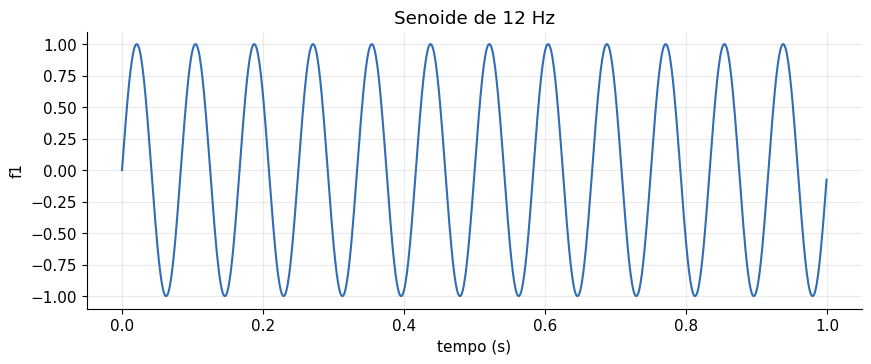

In [8]:
freq = 12                       # frequência em Hz
f1 = np.sin(2*np.pi*freq*t)

plt.plot(t, f1, color=AZUL)
plt.xlabel('tempo (s)'); plt.ylabel('f1'); plt.title(f'Senoide de {freq} Hz'); plt.show()

Conte as ondas no gráfico: são **5 em 1 segundo**. Cada onda dura 1/5 = 0,2 s. Guarde esta conta, que vai voltar várias vezes:

**período = 1 / frequência**

### Passo 3 — A FFT
Duas linhas calculam a FFT, e o resto é só o gráfico:
* `np.fft.rfft` faz a conta, `np.abs` transforma o resultado em **quanto tem**, e `* 2 / len(f1)` só acerta a escala;
* `np.fft.rfftfreq` diz **a qual frequência** corresponde cada valor.

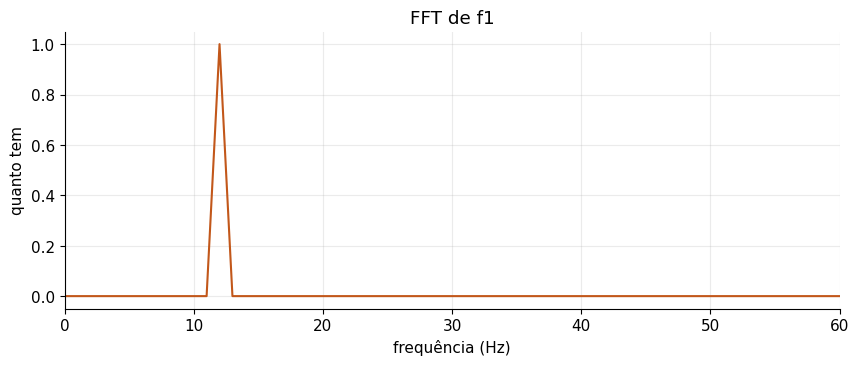

In [9]:
A = np.abs(np.fft.rfft(f1)) * 2 / len(f1)       # quanto tem de cada frequência
freqs = np.fft.rfftfreq(len(f1), 1/fs)          # as frequências

plt.plot(freqs, A, color=LARANJA)
plt.xlabel('frequência (Hz)'); plt.ylabel('quanto tem'); plt.title('FFT de f1')
plt.xlim(0, 60); plt.show()

> 📸 **Entrega 1** — Print da **FFT de f1**. ✍️ Em que frequência está o pico, e qual é a altura dele?
> Depois teste no Passo 2: troque `freq` para **12** e rode as duas células. Em seguida, escreva `f1 = 3*np.sin(2*np.pi*freq*t)` e rode de novo.
> O que muda no pico em cada caso? (Depois volte para `freq = 5`, sem o 3.)

### Passo 4 — Várias senoides, vários picos
Vamos criar três senoides, cada uma com sua frequência e sua altura, e ver **uma de cada vez**.

In [ ]:
f1 = 2.0 * np.sin(2*np.pi*5*t)
f2 = 1.0 * np.sin(2*np.pi*20*t)
f3 = 0.5 * np.sin(2*np.pi*50*t)

plt.plot(t, f1, label='f1: 5 Hz')
plt.plot(t, f2, label='f2: 20 Hz')
plt.plot(t, f3, label='f3: 50 Hz')
plt.xlim(0, 0.5); plt.xlabel('tempo (s)'); plt.title('As três senoides'); plt.legend(); plt.show()

Agora vamos somar. Para não repetir as mesmas linhas toda hora, a conta da FFT e os gráficos já estão em três funções prontas:
* `f, A = espectro(sinal, fs)` faz a **FFT** do Passo 3;
* `ver_sinal(...)` plota o sinal no **tempo**;
* `ver_espectro(...)` plota a **FFT**. Com `marcar=2`, ele escreve o valor de 2 picos no gráfico.

Primeiro, duas senoides somadas:

In [ ]:
soma2 = f1 + f2

ver_sinal(soma2, fs, 'f1 + f2 no tempo', ate=0.5)

f, A = espectro(soma2, fs)
ver_espectro(f, A, 'FFT de f1 + f2', ate=60, marcar=2, cor=LARANJA)

Agora, as três. No tempo fica difícil de ler. Na FFT, continua fácil:

In [ ]:
soma3 = f1 + f2 + f3

ver_sinal(soma3, fs, 'f1 + f2 + f3 no tempo', ate=0.5)

f, A = espectro(soma3, fs)
ver_espectro(f, A, 'FFT de f1 + f2 + f3', ate=60, marcar=3, cor=LARANJA)

> 📸 **Entrega 2** — Print da **FFT de f1 + f2 + f3**. ✍️ Quais são as três frequências e a altura de cada pico?
> Troque o `20` de `f2` por `30`, rode as células do Passo 4 de novo e diga o que mudou. (Depois volte para 20.)

### Passo 5 — Desafio: o sinal misterioso
Este sinal é a soma de **duas senoides**, com um pouco de ruído. As frequências **dependem do seu grupo**. Olhando o tempo, não dá para saber quais são. E olhando a FFT?

In [ ]:
misterio = sinal_misterioso(t)

ver_sinal(misterio, fs, 'O sinal misterioso', ate=0.5)

f, A = espectro(misterio, fs)
ver_espectro(f, A, 'FFT do sinal misterioso', ate=100, cor=LARANJA)

In [ ]:
freq_a = ___        # a frequência do primeiro pico (leia no gráfico)
freq_b = ___        # a frequência do segundo pico

confere_misterio(freq_a, freq_b)

> ✍️ **Entrega 3** — Quais são as **duas frequências** do seu grupo? (Precisa aparecer ✅.)

### Passo 6 — O primeiro filtro
Um filtro **apaga uma parte da FFT** e volta para o tempo. Vamos pegar `soma3` (5, 20 e 50 Hz) e deixar **só a senoide de 5 Hz**.

Um **passa-baixa** deixa passar o que está abaixo de `f_corte`. Escolha um valor olhando o gráfico da FFT do Passo 4:

In [ ]:
f_corte = ___       # deixe passar 5 Hz e corte 20 e 50 Hz

confere_faixa(f_corte, 6, 19, 'f_corte')

f, A = espectro(soma3, fs)
ver_filtro(f, A, 'passa-baixa', f_corte, titulo='O filtro: verde passa, cinza é cortado', ate=60)

so_grave = passa_baixa(soma3, fs, f_corte)
ver_sinal(so_grave, fs, 'Depois do passa-baixa', ate=0.5, cor=LARANJA)

f, A = espectro(so_grave, fs)
ver_espectro(f, A, 'FFT depois do passa-baixa', ate=60, cor=LARANJA)

Os outros dois filtros funcionam do mesmo jeito. Rode e compare:

In [ ]:
so_agudo = passa_alta(soma3, fs, 35)            # deixa passar acima de 35 Hz
so_meio = passa_faixa(soma3, fs, 10, 35)        # deixa passar de 10 a 35 Hz

ver_sinal(so_agudo, fs, 'Passa-alta de 35 Hz', ate=0.5)
ver_sinal(so_meio, fs, 'Passa-faixa de 10 a 35 Hz', ate=0.5)

> 📸 **Entrega 4** — Print de **"Depois do passa-baixa"**. ✍️ Que senoide sobrou em cada um dos três filtros?

**✅ Checklist da Parte 1**
- [ ] Criei o tempo, uma senoide e a FFT dela
- [ ] Vi que cada senoide vira um pico
- [ ] Li as frequências do sinal misterioso
- [ ] Usei um filtro para apagar picos

---
# Parte 2 — Funções que você já conhece

A rotina é sempre a mesma: **gerar → plotar → FFT → plotar**. Agora as funções imitam coisas reais, e **cada forma de onda deixa uma marca diferente na FFT**. ⭐ Tudo aqui é a mais, menos a onda quadrada do Caso 3 (🔁).
Vamos usar 10 000 pontos por segundo, porque estes sinais são mais rápidos.

### Caso 1 — A tomada de Jacareí
Uma senoide de 60 Hz, com pico de 110 V.

In [ ]:
fs = 10000
t = np.arange(0, 1, 1/fs)

tomada = 110 * np.sin(2*np.pi*60*t)
ver_sinal(tomada, fs, 'Tomada de Jacareí', ate=0.05)

f, A = espectro(tomada, fs)
ver_espectro(f, A, 'FFT da tomada', ate=500, marcar=1, cor=LARANJA)

### Caso 2 — O retificador de onda completa
O retificador da aula de 01/10 inverte a parte negativa. Em Python, isso é o **valor absoluto**: `np.abs`.
Agora é você: troque o `___` pelo nome do sinal que queremos analisar.

In [ ]:
retificado = np.abs(tomada)
ver_sinal(retificado, fs, 'Depois do retificador', ate=0.05)

f, A = espectro(___, fs)
ver_espectro(f, A, 'FFT do retificador', ate=500, marcar=4, cor=LARANJA)

> 📸 **Entrega 5** — Print da **FFT do retificador**. ✍️ Quais são os picos marcados? Olhando o gráfico no tempo, explique por que o primeiro pico **não** está mais em 60 Hz.

### Caso 3 — O clock de um processador
Um clock é uma **onda quadrada**. Aqui fazemos uma, bem lenta, de 50 Hz: `np.sign` devolve +1 quando a senoide é positiva e −1 quando é negativa.

In [ ]:
clock = np.sign(np.sin(2*np.pi*50*t))
ver_sinal(clock, fs, 'Clock (onda quadrada) de 50 Hz', ate=0.05)

f, A = espectro(___, fs)
ver_espectro(f, A, 'FFT do clock', ate=500, marcar=5, cor=LARANJA)

🔁 **Igual ao professor:** agora monte a onda quadrada **somando senoides**, uma de cada vez. Troque `n_harmonicos` para 1, 3, 9 e 49.

In [ ]:
n_harmonicos = 9

fs_q = 20_000
t_q = np.arange(0, 0.02, 1/fs_q)
soma = np.zeros_like(t_q)
for n in range(1, n_harmonicos + 1):
    k = 2*n - 1                                   # só os ímpares: 1, 3, 5, ...
    soma = soma + (4/np.pi) * np.sin(2*np.pi*k*100*t_q) / k

plt.plot(t_q*1000, soma, color=AZUL, lw=2)
plt.xlabel('tempo (ms)'); plt.ylabel('valor'); plt.title(f'Soma de {n_harmonicos} senoides'); plt.show()

f, A = espectro(soma, fs_q)
ver_espectro(f, A, f'FFT da soma de {n_harmonicos} senoides', ate=200*n_harmonicos + 100, marcar=min(n_harmonicos, 5), cor=LARANJA)

### Caso 4 — Uma corda de violão
Uma corda não vibra só em uma frequência: ela vibra na nota principal e em múltiplos dela. `np.exp(-3*t)` faz o som ir morrendo com o tempo.
*(Não precisa de som: basta olhar.)*

In [ ]:
violao = (1.0 * np.sin(2*np.pi*110*t) + 0.6 * np.sin(2*np.pi*220*t) + 0.3 * np.sin(2*np.pi*330*t)) * np.exp(-3*t)
ver_sinal(violao, fs, 'Corda de violão', ate=1)

f, A = espectro(___, fs)
ver_espectro(f, A, 'FFT da corda de violão', ate=500, marcar=3, cor=LARANJA)

> 📸 **Entrega 6** — Print da **FFT do clock**. ✍️ Os picos são quantas vezes a frequência básica de 50 Hz? Como se chamam esses picos?
> O que acontece com as quinas da onda quadrada quando `n_harmonicos` aumenta?

### Caso 5 — A temperatura de uma sala
Agora um sinal lento: a temperatura medida **uma vez por hora**, durante **60 dias**, com um ruído por cima (estes números são inventados).
Com um ponto por hora, `fs = 1`, e a frequência sai em **ciclos por hora**. O período, então, sai em **horas**.

In [ ]:
horas = np.arange(0, 24*60)         # 60 dias, hora a hora
ruido = np.random.default_rng(GRUPO).normal(size=len(horas))
temperatura = 22 + 5*np.sin(2*np.pi*horas/24) + 2*ruido

ver_sinal(temperatura, 1, 'Temperatura: a primeira semana', ate=24*7, unidade='horas')

f, A = espectro(temperatura, 1)
f_pico = picos(f, A, n=1)[0]

periodo = ___                       # período = 1 / frequência; a frequência é f_pico

confere(periodo, 24, 'período em horas')
ver_periodos(f, A, [f_pico], 'horas', 5, 100, 'FFT da temperatura, com o eixo em período')

> 📸 **Entrega 7** — Print da **FFT da temperatura**. ✍️ De quanto em quanto tempo a temperatura se repete, e por quê?

**✅ Checklist da Parte 2**
- [ ] Fiz a FFT de cinco funções diferentes
- [ ] Sei o que é um harmônico
- [ ] Transformei frequência em período

---
# Parte 3 — Dados reais: do segundo ao século

Agora os dados são **de verdade**, e a rotina continua a mesma.

## 🔁 Igual ao professor — O CO₂ da atmosfera

A medição mensal de CO₂ em Mauna Loa, no Havaí, desde 1958. Com um ponto por mês, `fs = 1` e o período sai em **meses**.

In [ ]:
co2 = pd.read_csv(baixar('dados/co2_mauna_loa.csv'))['co2_ppm'].values       # um ponto por mês: fs = 1

ver_sinal(co2, 1, 'CO₂ na atmosfera desde 1958', unidade='meses')
ver_sinal(co2, 1, 'Zoom: os primeiros 5 anos', ate=60, unidade='meses')

f, A = espectro(co2, 1)
ver_periodos(f, A, picos(f, A, n=2, f_min=1/15), 'meses', 3, 40, 'FFT do CO₂, com o eixo em período')

Agora separe a **subida** do **zigue-zague**. Use o mesmo corte da demonstração: um ciclo a cada 24 meses, ou seja, `1/24`.

In [ ]:
f_corte = ___
respiracao = None

confere(f_corte, 1/24, 'f_corte')

if preenchido(f_corte):
    # A FFT supõe que o sinal se repete: o fim emendaria no começo, com um salto enorme.
    # Espelhando a série, o fim encontra ele mesmo, e o salto some. Depois guardamos só a primeira metade.
    espelhada = np.concatenate([co2, co2[::-1]])
    subida = passa_baixa(espelhada, 1, f_corte)[:len(co2)]
    respiracao = passa_alta(espelhada, 1, f_corte)[:len(co2)]

    f, A = espectro(co2, 1)
    ver_filtro(f, A, 'passa-baixa', f_corte, titulo='Passa-baixa: fica só o que é mais lento que 24 meses', em_periodo=True, unidade='meses', de=3, ate=400, topo=6)
    ver_sinal(subida, 1, 'O que o passa-baixa guardou: a tendência', unidade='meses', cor=LARANJA)

    ver_filtro(f, A, 'passa-alta', f_corte, titulo='Passa-alta: fica só o que é mais rápido que 24 meses', em_periodo=True, unidade='meses', de=3, ate=400, topo=6)
    ver_sinal(respiracao, 1, 'O que o passa-alta guardou: o ciclo anual (primeiros 10 anos)', ate=120, unidade='meses', cor=LARANJA)

No gráfico do filtro, o **verde é o que passa** e o **cinza é o que é cortado**. A tendência é tão alta que sai do gráfico.
O **passa-baixa isola a tendência**, e o **passa-alta retira a tendência**.

### Ciclo de verdade ou só harmônico?
Apareceu um pico em **6 meses**. Será que acontece algo a cada 6 meses no planeta, ou é só um harmônico? A FFT sozinha não decide: um harmônico é uma senoide de verdade na soma, e o pico é igual nos dois casos. Vamos investigar **a forma** da curva e **se ela muda com o tempo**.

In [ ]:
tabela = pd.read_csv(baixar('dados/co2_mauna_loa.csv'))

ver_ciclo_ou_harmonico(respiracao, tabela['mes'].values, tabela['ano'].values)

> 📸 **Entrega 8** — Print da **FFT do CO₂**. ✍️ Quais são os dois picos, em meses? O que cada filtro guardou?

💬 **Para discutir em sala (não precisa escrever):** olhe "A forma do ano". Quanto tempo o CO₂ leva subindo, e quanto leva caindo? Uma senoide faria isso? Então o pico de 6 meses parece um ciclo próprio ou um harmônico?

---
## ⭐ A mais: suba na escala de tempo

Do **coração** (menos de 1 segundo) ao **consumo de energia** e à **maré** (horas e dias), até o **ciclo do Sol** (anos).

## ❤️ Missão 1 — O eletrocardiograma ruidoso

Abaixo está um **eletrocardiograma real** de 20 segundos (de um banco público de registros médicos),
ao qual somamos dois problemas muito comuns no hospital:
* a **interferência da tomada**, que entra pelos cabos;
* uma **deriva lenta**, que acontece quando a pessoa respira ou se mexe.

Sua missão: **limpar o sinal e descobrir os batimentos por minuto (bpm)**.

### Passo 1 — Olhar o sinal e o espectro

In [ ]:
fs_ecg = 360          # o aparelho mede 360 vezes por segundo
ecg = np.loadtxt(baixar(f'dados/ecg_grupo{GRUPO:02d}.csv'), skiprows=1)

ver_sinal(ecg, fs_ecg, 'Eletrocardiograma com ruído: cadê o coração?')

f, A = espectro(ecg, fs_ecg)
ver_espectro(f, A, 'Espectro: visão geral', ate=140, marcar=2)
ver_espectro(f, A, 'Zoom nas frequências muito baixas', ate=5, marcar=2)

> 📸 **Entrega 9** — Print do **espectro (visão geral)**. ✍️ De onde vêm os picos de **60 Hz** e **120 Hz**?

### Passo 2 — Filtrar
O coração fica entre os dois problemas. O exame costuma manter de **0,5 Hz** até **40 Hz**. Que filtro faz isso? Complete (em Python, com ponto: `0.5`):

In [ ]:
f_baixo = ___
f_alto  = ___

confere_faixa(f_baixo, 0.3, 0.7, 'f_baixo')
confere_faixa(f_alto, 25, 55, 'f_alto')

f, A = espectro(ecg, fs_ecg)
ver_filtro(f, A, 'passa-faixa', f_baixo, f_alto, titulo='O filtro: verde passa, cinza é cortado', ate=140)

ecg_limpo = passa_faixa(ecg, fs_ecg, f_baixo, f_alto)
ver_sinal(ecg_limpo, fs_ecg, 'Eletrocardiograma limpo', ate=10, cor=LARANJA)

> 📸 **Entrega 10** — Print do **eletrocardiograma limpo**. ✍️ **Conte os picos altos** nesses 10 segundos e multiplique por 6: quantos batimentos por minuto dá?

### Passo 3 — A FFT mede o batimento
O coração é um sinal **periódico**, então ele deve aparecer como um pico. Se o coração bate *f* vezes por segundo,
são **60 × f** batimentos por minuto. Procuramos o pico só entre 0,8 e 3 Hz (de 48 a 180 bpm). Complete a conta:

In [ ]:
if ecg_limpo is None:
    print('⏳ complete o Passo 2')
else:
    f, A = espectro(ecg_limpo, fs_ecg)
    ver_espectro(f, A, 'Espectro do sinal limpo, perto do batimento', de=0.8, ate=4, marcar=1, cor=LARANJA)
    f_coracao = picos(f, A, n=1, f_min=0.8, f_max=3)[0]
    print(f'pico do coração: {f_coracao:.2f} Hz')

    bpm = ___           # transforme f_coracao em batimentos por minuto

    if bpm is None:
        print('⏳ complete a conta do bpm')
    else:
        confere(bpm, f_coracao * 60, 'bpm')

> ✍️ **Entrega 11** — Quanto deu o **bpm pela FFT**, e ele concorda com a sua **contagem**?

**✅ Checklist da Missão 1**
- [ ] Identifiquei a tomada dentro de um exame médico
- [ ] Limpei o sinal com um passa-faixa
- [ ] Medi os batimentos de dois jeitos

---
## 🔎 Missão 2 — Detetive de períodos

Até agora o espectro ajudou a **limpar**. Agora ele vai ajudar a **descobrir**: qual é o ritmo escondido em dados reais?

A conta-chave é uma só: **período = 1 / frequência**. A unidade depende de como o dado foi medido:
se há **um ponto por hora**, então `fs = 1` e a frequência sai em **ciclos por hora** (e o período, em **horas**).

### Caso 1 — O consumo de energia do Sudeste

Temos o consumo de energia elétrica do **Sudeste do Brasil em 2024**, hora a hora (dados do ONS, o operador do sistema elétrico).

> ✍️ **Entrega 12 (antes de rodar!)** — Dê um **palpite**: de quanto em quanto tempo você acha que o consumo se repete?
> Escreva pelo menos dois ritmos. *Não vale mudar depois: palpite errado não perde ponto.*

In [ ]:
energia = pd.read_csv(baixar('dados/energia_sudeste_2024.csv'))['carga_MW'].values

ver_sinal(energia, 1, 'Consumo de energia: as três primeiras semanas de 2024', ate=24*21, unidade='horas')

f, A = espectro(energia, 1)      # 1 ponto por hora
os_picos = picos(f, A, n=4, f_min=1/400)

ver_periodos(f, A, os_picos, 'horas', 5, 400, 'Espectro do consumo, com o eixo em período')

Agora complete o `for`: para cada pico, calcule o **período** usando `f_pico`.

In [ ]:
for f_pico in os_picos:
    periodo = ___                 # período = 1 / frequência
    if periodo is None:
        print('⏳ complete a conta do período')
        break
    print(f'{f_pico:.5f} ciclos por hora  ->  a cada {periodo:6.1f} horas  =  {periodo/24:5.2f} dias')

> 📸 **Entrega 13** — Print do **espectro em período** e da **tabela de períodos**. ✍️ O que, na sua rotina, explica os picos de **24 horas** e de cerca de **7 dias**?

> ✍️ **Entrega 14** — Apareceram também **12 horas** e cerca de **84 horas (3,5 dias)**. Ninguém tem uma rotina de 12 horas!
> Dica: lembre do **clock** da Parte 2 e compare 12 com 24, e 84 com 168. Como se chamam esses picos?

### Caso 2 — A maré de Ubatuba

Agora o nível do mar em **Ubatuba, em 2015**, hora a hora. Tem **duas marés altas por dia**, então o palpite óbvio é **12 horas**. Será?

In [ ]:
mare = pd.read_csv(baixar('dados/mare_ubatuba_2015.csv'))['nivel_m'].values

ver_sinal(mare, 1, 'Nível do mar em Ubatuba: os 10 primeiros dias de 2015', ate=24*10, unidade='horas')

f, A = espectro(mare, 1)
os_picos = picos(f, A, n=2, f_min=1/30)
ver_periodos(f, A, os_picos, 'horas', 8, 30, 'Espectro da maré, com o eixo em período')

for f_pico in os_picos:
    print(f'a cada {1/f_pico:.2f} horas')

> 📸 **Entrega 15** — Print do espectro. ✍️ Qual é o **maior pico**, em **horas e minutos**? (Exemplo: 12,5 h = 12 h 30 min.)
> Ele é **exatamente** 12 horas?

**O detalhe que entrega a Lua.** A Terra gira, mas a Lua também anda na órbita dela. Por isso, a Lua leva cerca de
**24 h 50 min** para voltar ao mesmo ponto do céu, e não 24 h. Como são duas marés nesse tempo: 24 h 50 min ÷ 2 = **12 h 25 min**.
O pico de **exatamente 12 h** é a maré causada pelo **Sol**. A FFT separou os dois astros usando só uma régua no mar de Ubatuba!

### Caso 3 — As manchas solares

Astrônomos contam as manchas na superfície do Sol **desde 1749**. Temos a média de **cada mês**, ou seja, **12 pontos por ano**.
Com `fs = 12`, a frequência sai em **ciclos por ano** e o período, em **anos**. Complete o `fs`:

In [ ]:
manchas = pd.read_csv(baixar('dados/manchas_solares.csv'))['manchas'].values

fs_sol = ___          # quantos pontos por ano?

if fs_sol is None:
    print('⏳ complete o fs_sol')
else:
    confere(fs_sol, 12, 'fs_sol')
    ver_sinal(manchas, fs_sol, 'Manchas solares desde 1749', unidade='anos desde 1749')
    f, A = espectro(manchas, fs_sol)
    o_pico = picos(f, A, n=1, f_min=1/40)
    ver_periodos(f, A, o_pico, 'anos', 2, 40, 'Espectro das manchas solares, com o eixo em período')

> 📸 **Entrega 16** — Print do espectro das manchas solares. ✍️ De quantos em quantos **anos** o Sol repete o ciclo?
> Por que precisamos de **tantos anos** de dados para enxergar esse pico?

**✅ Checklist da Missão 2**
- [ ] Transformei frequência em período
- [ ] Sei o que é um harmônico no consumo de energia
- [ ] Vi a Lua e o Sol no espectro da maré

---
# Parte 4 — Som

Som também é um sinal. O seu computador não precisa tocar nada: a FFT **enxerga** o som.

## 🔁 Igual ao professor — Limpar uma voz, só olhando

É a mesma voz da demonstração, com **chiado** por cima. Como não temos som aqui, vamos conferir pelo gráfico e por um número: o quanto o sinal **se parece** com a voz original.

In [ ]:
fs_v, voz = wavfile.read(baixar('audios/0_voz_limpa.wav'))
fs_v, suja = wavfile.read(baixar('audios/2_chiado_antes.wav'))
voz = voz / 32768
suja = suja / 32768

ver_sinal(voz, fs_v, 'A voz original')
ver_sinal(suja, fs_v, 'A voz com chiado: cadê a voz?', cor=CINZA)

f, A = espectro(suja, fs_v)
ver_espectro(f, A, 'Espectro da voz com chiado', ate=11000, cor=CINZA)

print(f'Parecido com a voz original: {parecido(suja, voz):.0f}%')

A voz fica nos graves, e o chiado começa perto de 2600 Hz. Que filtro separa os dois? Complete o corte:

In [ ]:
f_corte = ___

confere_faixa(f_corte, 1500, 2600, 'f_corte')

f, A = espectro(suja, fs_v)
ver_filtro(f, A, 'passa-baixa', f_corte, titulo='O filtro: verde passa, cinza é cortado', ate=11000)

limpa = passa_baixa(suja, fs_v, f_corte)

if limpa is not None:
    ver_sinal(limpa, fs_v, 'Depois do passa-baixa', cor=LARANJA)
    f, A = espectro(limpa, fs_v)
    ver_espectro(f, A, 'Espectro depois do passa-baixa', ate=11000, cor=LARANJA)
    print(f'Parecido com a voz original: {parecido(limpa, voz):.0f}%')

> 📸 **Entrega 17** — Print de **"Depois do passa-baixa"**. ✍️ Quanto o sinal se parecia com a voz **antes** e **depois** do filtro?

*Em casa, com som, ouça o resultado: `from IPython.display import Audio; Audio(limpa, rate=fs_v)`.*

---
## ⭐ Extra: 🕵️ Missão 3 — O código escondido nos tons de telefone

*Se o tempo acabar, deixe esta missão para o fim e termine em casa.*

Quando você aperta uma tecla do telefone, ele envia **duas senoides somadas**: uma da linha e uma da coluna da tecla.
É assim que a central sabe o que foi digitado (ainda se usa no "digite 1 para falar com o atendente").

| | **1209 Hz** | **1336 Hz** | **1477 Hz** |
|---|---|---|---|
| **697 Hz** | 1 | 2 | 3 |
| **770 Hz** | 4 | 5 | 6 |
| **852 Hz** | 7 | 8 | 9 |
| **941 Hz** | * | 0 | # |

Interceptamos uma gravação com **6 teclas**, **uma por segundo**. Só que a linha estava péssima:
tem um **zumbido** forte e um **chiado**. Sua missão: **descobrir o código de 6 dígitos**.

*(Não precisa de som: você vai descobrir tudo só olhando.)*

### Passo 1 — Olhar o sinal e o espectro

In [ ]:
fs, sinal = wavfile.read(baixar(f'dados/tons_grupo{GRUPO:02d}.wav'))
sinal = sinal / 32768

ver_sinal(sinal, fs, 'A gravação', ate=2)

f, A = espectro(sinal, fs)
ver_espectro(f, A, 'Espectro da gravação inteira')
ver_espectro(f, A, 'Zoom: de 0 a 300 Hz', ate=300, marcar=2)

> 📸 **Entrega 18** — Print do **espectro da gravação inteira**. ✍️ Em que faixas de frequência estão o **zumbido** e o **chiado**?

### Passo 2 — Escolher o filtro
Queremos manter **só a região das teclas**, cortando o que está abaixo (zumbido) e acima (chiado). Isso é um **passa-faixa**.
Complete as duas frequências:

In [ ]:
f_baixo = ___       # abaixo disto, corta (precisa cortar o zumbido e manter 697 Hz)
f_alto  = ___       # acima disto, corta  (precisa manter 1477 Hz e cortar o chiado)

confere_faixa(f_baixo, 200, 690, 'f_baixo')
confere_faixa(f_alto, 1480, 2200, 'f_alto')

f, A = espectro(sinal, fs)
ver_filtro(f, A, 'passa-faixa', f_baixo, f_alto, titulo='O filtro: verde passa, cinza é cortado', ate=4000)

limpo = passa_faixa(sinal, fs, f_baixo, f_alto)
ver_sinal(limpo, fs, 'Depois do filtro: agora dá para ver as teclas!')

> ✍️ **Entrega 19** — Por que nem um **passa-baixa** nem um **passa-alta** resolveriam sozinhos?

### Passo 3 — A primeira tecla, à mão
Cada tecla ocupa **1 segundo**, ou seja, `fs` pontos. Vamos olhar o espectro só do primeiro segundo e ler os dois picos.

In [ ]:
if limpo is None:
    print('⏳ complete o Passo 2')
else:
    trecho = limpo[0 : fs]              # primeiro segundo
    f, A = espectro(trecho, fs)
    duas = picos(f, A, n=2)
    ver_espectro(f, A, 'Primeira tecla', de=500, ate=1800, marcar=2)
    print('As duas frequências:', duas)

> 📸 **Entrega 20** — Print do espectro da primeira tecla. ✍️ Use a tabela lá em cima: **que tecla é essa?**

### Passo 4 — As 6 teclas com um `for`
Fazer à mão 6 vezes é chato: isso é trabalho para o computador. Complete o laço:
* `n` é **quantas frequências** cada tecla tem;
* a função `tecla(f1, f2)` consulta a tabela para você.

In [ ]:
codigo = ''

if limpo is None:
    print('⏳ complete o Passo 2')
else:
    for k in range(6):
        trecho = limpo[k*fs : (k+1)*fs]         # o segundo número k
        f, A = espectro(trecho, fs)
        duas = picos(f, A, n=___)               # quantos picos cada tecla tem?
        digito = tecla(duas[0], duas[1])
        print(f'tecla {k+1}: {duas}  ->  {digito}')
        codigo = codigo + digito

    print('\nCódigo:', codigo)
    confere_segredo('codigo', codigo)

> ✍️ **Entrega 21** — Qual é o **código do seu grupo**? (Precisa aparecer 🎉.)

**✅ Checklist da Missão 3**
- [ ] Sei dizer onde estão o zumbido e o chiado no espectro
- [ ] Escolhi o filtro olhando o espectro
- [ ] Descobri o código e apareceu 🎉

---
# Parte 5 — Imagem

🔁 O **Passo 1** é igual ao da demonstração. ⭐ Depois, a imagem do seu grupo traz outra palavra escondida.

## 🖼️ Missão 4 — A palavra escondida na imagem

Uma imagem também é um sinal: em vez de variar no **tempo**, ela varia no **espaço**.
* **Frequência baixa:** regiões que mudam devagar (céu, parede, pele).
* **Frequência alta:** mudanças rápidas (bordas e detalhes).

No espectro de uma imagem, o **centro** são as frequências baixas. Quanto mais **longe do centro**, mais alta a frequência.

### Passo 1 — Passa-baixa e passa-alta em uma foto
Mude o `raio` e rode de novo: ele é o tamanho do círculo do espectro em torno do centro.

In [ ]:
foto = ler_imagem('dados/astronauta.png')

raio = 20         # teste 5, 20 e 80

ver_filtro_imagem(foto, raio)

**O que você está vendo.** Em cima, as imagens. Embaixo, o pedaço do espectro que cada filtro guardou:
* **Original:** o centro do espectro é o mais brilhante, porque a maior parte de uma foto muda devagar.
* **Passa-baixa:** guarda só o círculo central. Sem frequências altas, nada pode mudar de repente, e a foto fica borrada.
* **Passa-alta:** apaga o círculo central. Somem a iluminação e as áreas lisas, e sobram as bordas, sobre um fundo cinza, que é o zero.

> 📸 **Entrega 22** — Print das três imagens. ✍️ O que o **passa-baixa** faz com a foto? O que sobra no **passa-alta**?

### Passo 2 — A imagem do seu grupo
Esta imagem foi coberta com **listras**. Por baixo delas tem uma **palavra**. Tente ler (spoiler: não dá).

In [ ]:
secreta = ler_imagem(f'dados/imagem_grupo{GRUPO:02d}.png')

ver_imagens(('Imagem com listras', secreta), tamanho=6.5)

### Passo 3 — Olhar o espectro
Uma listra é uma **senoide na imagem**, então ela vira um **ponto brilhante** no espectro. Procure pontos brilhantes **isolados, longe do centro**.
Como o espectro é simétrico, cada listra aparece **duas vezes**, em lados opostos do centro.

In [ ]:
ver_espectro_imagem(secreta, zoom=70, titulo='Espectro: procure os pontos brilhantes isolados')

> 📸 **Entrega 23** — Print do espectro. ✍️ Anote as **coordenadas** dos pontos brilhantes: (x, y).
> Por que uma listra aparece como um **ponto**?

### Passo 4 — Apagar as listras
Escolha **dois** pontos que **não sejam espelho um do outro**: a função já apaga o espelho sozinha.
Pode errar por 2 ou 3 unidades, sem problema. Se ainda sobrar listra, olhe o espectro de novo e ajuste.

In [ ]:
pontos = [(___, ___), (___, ___)]        # (x do ponto 1, y do ponto 1), (x do ponto 2, y do ponto 2)

limpa = apagar_pontos(secreta, pontos)

if limpa is not None:
    ver_imagens(('Antes', secreta), ('Depois', limpa), tamanho=6.5)

### Passo 5 — A resposta
Escreva a palavra **entre aspas** e **em maiúsculas, sem acento**.

In [ ]:
palavra = ___       # exemplo: "CAPACITOR"

confere_segredo('palavra', palavra)

> 📸 **Entrega 24** — Print do **"Depois"**. ✍️ Qual é a **palavra** do seu grupo? (Precisa aparecer 🎉.)

**✅ Checklist da Missão 4**
- [ ] Vi o passa-baixa borrar e o passa-alta achar bordas
- [ ] Achei as listras no espectro
- [ ] Li a palavra e apareceu 🎉

---
## Fechamento

> ✍️ **Entrega 25** — Na demonstração em aula, o **ruído branco** não saiu da voz com nenhum filtro.
> Mas o **zumbido**, o **chiado** e as **listras** saíram. Use o que você viu no espectro para explicar: **quando um filtro consegue separar o sinal do ruído, e quando não consegue?**